In [1]:
import pickle
import os
from tqdm import tqdm
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
import matplotlib

#import models.vgg as models
#import models.densenet as models
import models.chexpert.classifier as classifier
from easydict import EasyDict as edict

torch.set_printoptions(sci_mode=False)

import lrp
from models.lrp_converter import convert

from PIL import Image, ImageDraw

from utils import get_device, heatmap, project

/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from dataset.dataset import load_data
from dataset.utils import *

def get_dataset(return_orig=False, return_path=False, shuffle=True):
    n_concepts = 13
    val_loader = load_data("../dataset/chexpert/splits/all_cheXbert_train_val_test/test.pkl", 32, dataset_root="../dataset/chexpert/", return_orig=return_orig, return_path=return_path, shuffle=shuffle, dataset_name="chexpert", x_resize=512, y_resize=512)
    concept_index_to_string = IndexToString("../dataset/chexpert/splits/all_cheXbert_train_val_test/concepts.txt")

    #val_loader = load_data("../dataset/chexpert/splits/all_class_level_2/test.pkl", 32, dataset_root="../dataset/chexpert/", return_orig=return_orig, return_path=return_path, shuffle=shuffle, dataset_name="chexpert", x_resize=512, y_resize=512)


    return n_concepts, val_loader, concept_index_to_string

In [47]:
device = get_device(cpu=True)

N_CONCEPT, test_loader, concept_index_to_string = get_dataset(return_orig=True, return_path=True, shuffle=True)

#XtoC = models.vgg19_bn(pretrained=True, num_classes=N_CONCEPT)

#backbone = models.densenet121(pretrained=False, num_classes=1000)
#XtoC = models.XtoC(backbone, global_pool_type="AVG_MAX", num_classes=[1,1,1,1,1], fc_bn=True, fc_drop=0, lse_gamma=0.5)

cfg = {
    "backbone": "densenet121",
    "norm_type": "BatchNorm",
    "pretrained": True,
    "num_concepts": 13,
    "cbm_mode": "joint",
    "xtoc_only": False
}

XtoCtoY = classifier.Classifier(cfg)

XtoCtoY.load_state_dict(torch.load("./../saves/chexpert/sequential_4.ckpt", map_location=torch.device('cpu'))['state_dict'], strict=False)
#XtoCtoY.load_state_dict(torch.load("./../saves/chexpert/joint_class_2_4.ckpt", map_location=torch.device('cpu'))['state_dict'], strict=False)

XtoCtoY.to(device)
XtoCtoY.eval()

print("model loaded")

Device: cpu NVIDIA GeForce RTX 3050 Ti Laptop GPU
model loaded


In [48]:
#XtoC = convert(XtoC).to(device)

#print(XtoC)

In [49]:
from torchmetrics import F1Score
from tqdm import tqdm
import torch.nn.functional as F
from torchmetrics.functional.classification import multilabel_auroc
from sklearn import metrics
from torch.autograd import Variable

def get_loss(output, target, index, pos_weight, device):
    target = target[:, index].view(-1)
    if pos_weight == None:
        if target.sum() == 0:
            loss = torch.tensor(0., requires_grad=True).to(device)
        else:
            weight = (target.size()[0] - target.sum()) / target.sum()
            loss = F.binary_cross_entropy_with_logits(output[:, index].view(-1), target, pos_weight=weight)
    else:
        pos_weight = torch.from_numpy(
            np.array(
                pos_weight,
                dtype=np.float32
            )).to(device).type_as(target)
        loss = F.binary_cross_entropy(
            output[:, index].view(-1), target, pos_weight=pos_weight[index])

    return loss

def binary_accuracy(output, target):
    """
    Computes the accuracy for multiple binary predictions.

    args:
        output (Pytorch tensor): Model prediction
        target (Pytorch tensor): Ground truth from dataset
    returns:
        acc: binary accuracy
    """
    pred = output >= 0.5
    acc = (pred.int()).eq(target.int()).sum()
    acc_per_concept = (pred.int()).eq(target.int()).sum(dim=0)
    acc = acc * 100 / np.prod(np.array(target.size()))
    acc_per_concept = acc_per_concept / pred.size(0)
    return acc, acc_per_concept

def test(model, data_loader, f1=None, auc_lib="sklearn", device="cpu"):
    """
    Training and evaluation loop.

        args:
            model (Pytorch model): Pytorch model to train / evaluate
            data_loader (Pytorch dataloader): Pytorch dataloader with dataset Initilised
            f1 (Pytorch torchmetrics F1): F1 metrics object
            device (str): Device top train / test using (e.g. cpu or cuda:0)

        returns:
            average loss: Average loss of model
            average accuracy: Average accuracy of concepts / task (non joint)
            average F1 score: Average F1 score of concepts / task (non joint)
            average task F1 score (joint only): Average task F1 score
            average task accuracy (joint only): Average task accuracy
    """

    model.train(False)

    running_loss = 0.0
    sample_count = 0
    accuracy = []
    true_concepts = []
    pred_concepts = []
    auc_acc = []
    task_accuracy = []

    with torch.set_grad_enabled(False):
        for data in tqdm(data_loader, unit="batch"):
            inputs, task_lables, labels, extra = data
            batch_size = inputs.shape[0]
            inputs = Variable(inputs.to(device))
            labels = Variable(labels.to(device)).float()

            if cfg["cbm_mode"] == "joint" and cfg["xtoc_only"] != True :
                concept_outputs, task_outputs = model(inputs)
            else:
                concept_outputs = model(inputs)
            sigmoid_outputs = torch.nn.Sigmoid()(concept_outputs)

            loss = 0
            for t in range(labels.shape[1]):
                loss_t = get_loss(concept_outputs, labels, t, None, device)
                loss += loss_t

            acc, acc_per_concept = binary_accuracy(sigmoid_outputs, labels)
            accuracy.append(acc.item())

            running_loss += loss.data * batch_size
            sample_count += batch_size

            # for auc metric
            true_concepts.append(labels.cpu().detach())
            pred_concepts.append(sigmoid_outputs.cpu().detach())

            if auc_lib != "sklearn":
                #print(multilabel_auroc(sigmoid_outputs, labels, num_labels=labels.size(1), average="macro", thresholds=None))
                #print(multilabel_auroc(sigmoid_outputs, labels, num_labels=labels.size(1), average=None, thresholds=None))
                auc_acc.append(multilabel_auroc(sigmoid_outputs, labels, num_labels=labels.size(1), average=None, thresholds=None))

            # task accuracy
            if cfg["cbm_mode"] == "joint" and cfg["xtoc_only"] != True :
                _, predicted = task_outputs.max(1)
                task_accuracy.extend(predicted.eq(task_lables))

            #if f1 is not None:
            #	f1_acc.append(f1(sigmoid_outputs, concepts.to(torch.int32)))

    epoch_loss = running_loss / sample_count

    true_concepts = torch.cat(true_concepts, dim=0)
    pred_concepts = torch.cat(pred_concepts, dim=0)
    auc_acc = torch.stack(auc_acc, dim=0)

    if auc_lib == "sklearn":
        auc = metrics.roc_auc_score(true_concepts.numpy(), pred_concepts.numpy())
    else:  # "torchmetrics"
        auc = auc_acc.mean(dim=0)

    if cfg["cbm_mode"] == "joint" and cfg["xtoc_only"] != True :
        return epoch_loss, sum(accuracy) / len(accuracy), auc, (sum(task_accuracy) / len(task_accuracy)).item()
    else:
        return epoch_loss, sum(accuracy) / len(accuracy), auc, None

In [50]:
f1 = F1Score().to(device)
testLoss, testAcc, testAuc, taskAcc = test(XtoCtoY, test_loader, f1=f1, auc_lib="torchmetrics", device=device)

testAuc =  testAuc[testAuc.nonzero()]  # remove 0 values from auc
print(f"Loss: {testLoss}, Acc: {testAcc}, AUC: {torch.mean(testAuc)} ({testAuc}), task accuracy: {taskAcc}")

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 21/21 [02:28<00:00,  7.07s/batch]

Loss: 6.841757297515869, Acc: 75.6704610188802, AUC: 0.659408688545227 (tensor([[0.6339],
        [0.8810],
        [0.9165],
        [0.4814],
        [0.9254],
        [0.6429],
        [0.3746],
        [0.8343],
        [0.3770],
        [0.9526],
        [0.3717],
        [0.2289],
        [0.9521]])), task accuracy: 0.8532934188842773


# Sample outputs from model

In [5]:
import json

# Opening JSON file
f = open('../dataset/chexpert/CheXlocalize/gt_annotations_val.json')
 
# returns JSON object as
# a dictionary
segmentations = json.load(f)
 
# Iterating through the json
# list
#print(data.keys())
 
# Closing file
f.close()

def get_human_segmentation(sample_key, concept_key, segmentations=segmentations):
	#print(segmentations.keys())
	#print(segmentations[sample_key]) # 'patient64961_study1_view1_frontal'
	#print(segmentations[sample_key].keys())
	#return segmentations[sample_key]
	
	if concept_key not in segmentations[sample_key].keys():
		return None
	
	for key in segmentations[sample_key]:
		print(key)
	
	polygons = segmentations[sample_key][concept_key]
	
	poly = Image.new('1', (segmentations[sample_key]["img_size"][1], segmentations[sample_key]["img_size"][0]))
	for polygon in polygons:
		coords = [(point[0], point[1]) for point in polygon]
		ImageDraw.Draw(poly).polygon(coords,  outline=1, fill=1)

	return poly

In [6]:
def plot(imgs, orig_img, with_orig=True, row_title=None, **imshow_kwargs):
	if not isinstance(imgs[0], list):
		# Make a 2d grid even if there's just 1 row
		imgs = [imgs]


	num_rows = len(imgs)
	num_cols = len(imgs[0]) + with_orig
	fig, axs = plt.subplots(nrows=num_rows, ncols=num_cols, squeeze=False)
	for row_idx, row in enumerate(imgs):
		row = [orig_img] + row if with_orig else row
		for col_idx, img in enumerate(row):
			if isinstance(img, torch.Tensor):
				img = img.permute(1, 2, 0)
			ax = axs[row_idx, col_idx]
			ax.imshow(np.asarray(img), **imshow_kwargs)
			ax.set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

	if with_orig:
		axs[0, 0].set(title='Original image')
		axs[0, 0].title.set_size(8)
	if row_title is not None:
		for row_idx in range(num_rows):
			axs[row_idx, 0].set(ylabel=row_title[row_idx])

	plt.tight_layout()

True image size (channels, width, height): torch.Size([3, 512, 512])
True  image concepts: tensor([1., 1., 1., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.])
patient64672_study1_view1_frontal


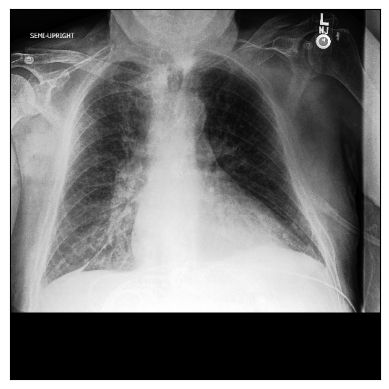

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


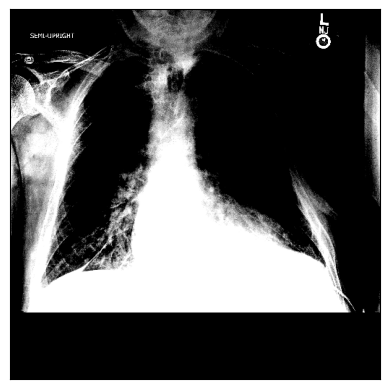

In [7]:
imageId = 7

images, labels, concepts, extra = next(iter(test_loader))
orig_imgs = extra["orig_img"]
image, label = images[imageId].to(device), labels[imageId].to(device)

# print / show input
print("True image size (channels, width, height):", image.size())
print("True  image concepts:", concepts[imageId])

segmentation_key = "_".join(extra["path"][imageId].split("/")[-3:]).split(".")[0]

print(segmentation_key)

plt.xticks([])
plt.yticks([])
plt.imshow(orig_imgs[imageId].squeeze())
plt.show()

plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

In [8]:
"""
image, concepts = transform(orig_image).to(device), torch.FloatTensor(samples[0][1]).to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction and LRP map for classification
prediction = XtoC(image)

print(prediction)

pred_concepts_readable = torch.nn.Sigmoid()(prediction)
print("Predicted concepts:", pred_concepts_readable)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")
"""


image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction
if cfg["cbm_mode"] == "joint" and cfg["xtoc_only"] != True :
	prediction_concepts, prediction_task = XtoC(image)
else:
	prediction_concepts = XtoC(image)

pred_concepts_readable = torch.nn.Sigmoid()(prediction_concepts)
print("Predicted concepts:", pred_concepts_readable)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")

Predicted concepts: tensor([[0.5543, 0.9347, 0.6843, 0.5103, 0.9781, 0.3166, 0.6938, 0.2286, 0.0839,
         0.2872, 0.4254, 0.3689, 0.1203]], grad_fn=<SigmoidBackward0>)
id: 0, concept name: enlarged_cardiomediastium, sig value: 0.5542793869972229
id: 1, concept name: cardiomegaly, sig value: 0.9346973896026611
id: 2, concept name: lung_opacity, sig value: 0.6843369603157043
id: 3, concept name: lung_lesion, sig value: 0.5103313326835632
id: 4, concept name: edema, sig value: 0.9780595898628235
id: 6, concept name: pneumonia, sig value: 0.693755030632019


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from captum.attr import IntegratedGradients, Saliency, GuidedGradCam
from captum.attr import NoiseTunnel
from captum.attr import visualization as viz

from dataset.utils import transform as chexpert_transform
seg_transform = chexpert_transform

In [10]:
import numpy as np
import matplotlib.pylab as pl
from matplotlib.colors import ListedColormap

base_cmap = pl.cm.seismic
seismic_alpha = base_cmap(np.arange(base_cmap.N))
seismic_alpha[:,-1] = np.concatenate((np.ones(115), (np.logspace(1, 0, 13)/10), (np.logspace(0, 1, 13)/10), np.ones(115)), axis=0)  # set alpha
seismic_alpha = ListedColormap(seismic_alpha)  # create new colormap

base_cmap = pl.cm.Greens
green_alpha = base_cmap(np.arange(base_cmap.N))
green_alpha[:,-1] = np.linspace(0, 1, 256)  # set alpha
green_alpha = ListedColormap(green_alpha)  # create new colormap

In [11]:
# Only get concept outputs for saliency map generation

cfg = {
	"backbone": "densenet121",
	"norm_type": "BatchNorm",
	"pretrained": True,
	"num_concepts": 13,
	"cbm_mode": "xtoc",
	"xtoc_only": True
}

XtoC = classifier.Classifier(cfg)

#XtoC.load_state_dict(torch.load("./../saves/chexpert_5_obs/best1.ckpt", map_location=torch.device('cpu'))['state_dict'], strict=False)
XtoC.load_state_dict(torch.load("./../saves/chexpert_test/joint_0_99/best1.ckpt", map_location=torch.device('cpu'))['state_dict'], strict=False)

XtoC.to(device)
XtoC.eval()

print("model loaded")

model loaded


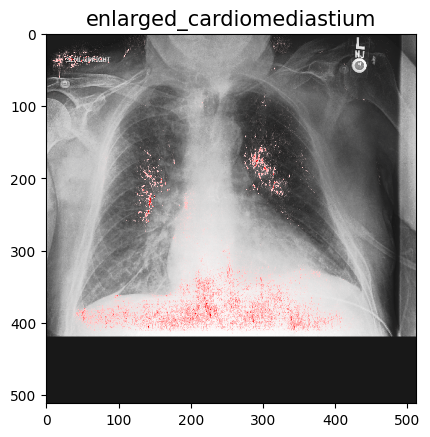

img_size
Cardiomegaly
Enlarged Cardiomediastinum
Edema
Airspace Opacity


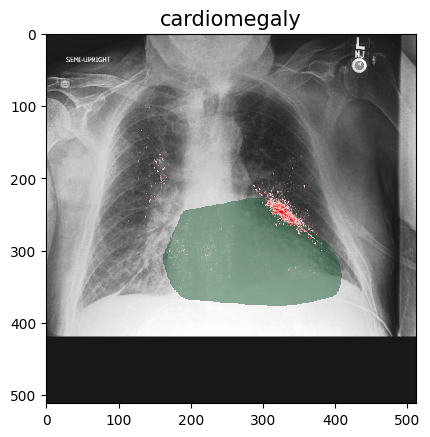

img_size
Cardiomegaly
Enlarged Cardiomediastinum
Edema
Airspace Opacity


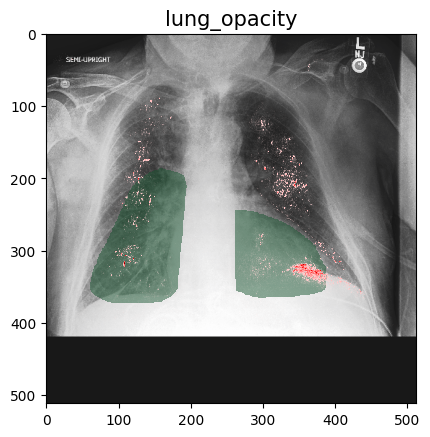

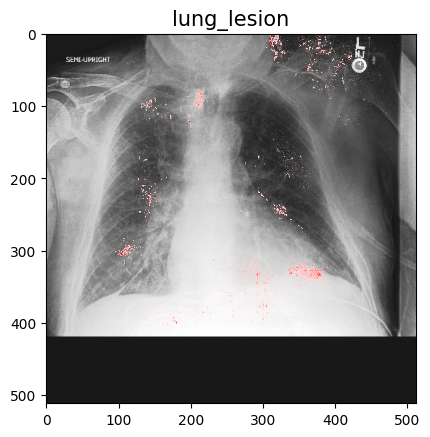

img_size
Cardiomegaly
Enlarged Cardiomediastinum
Edema
Airspace Opacity


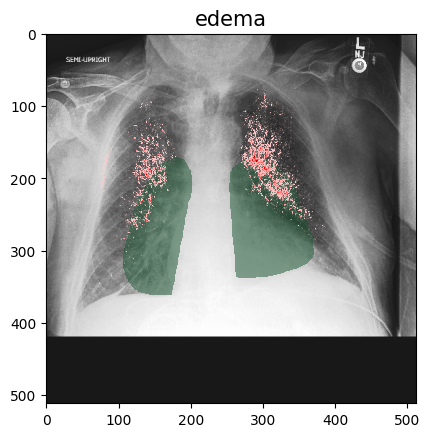

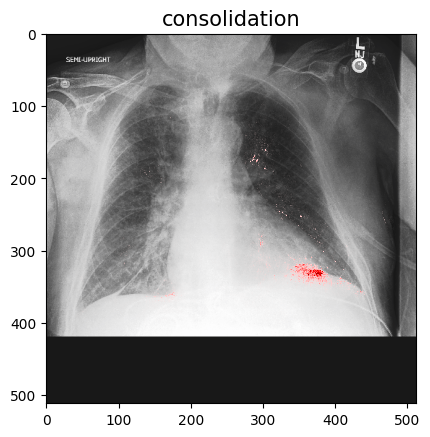

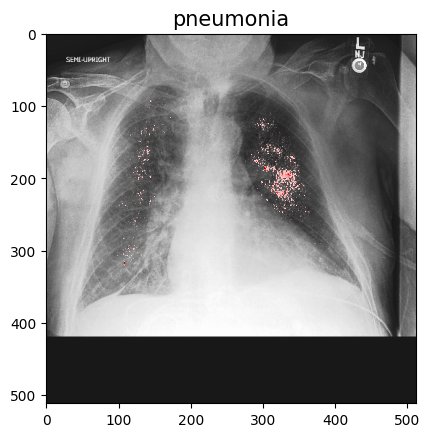

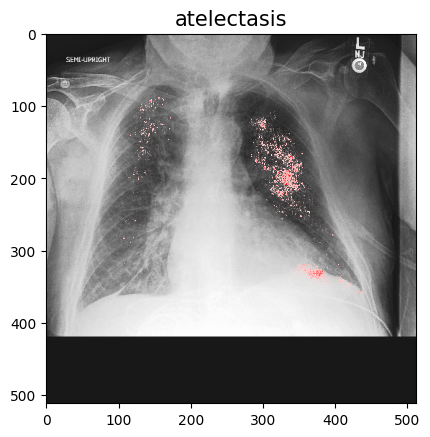

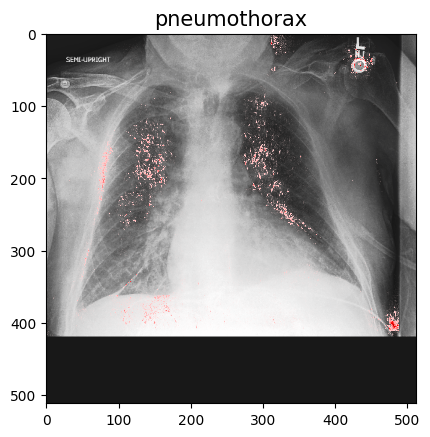

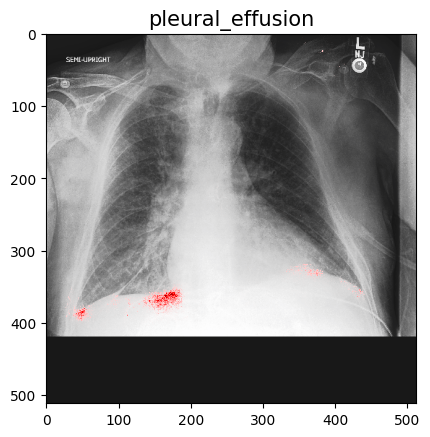

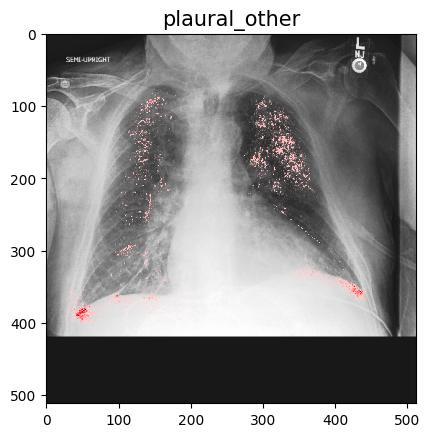

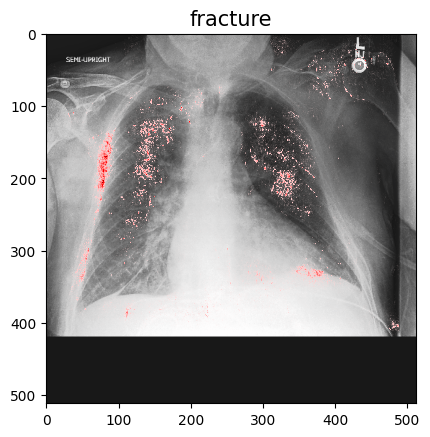

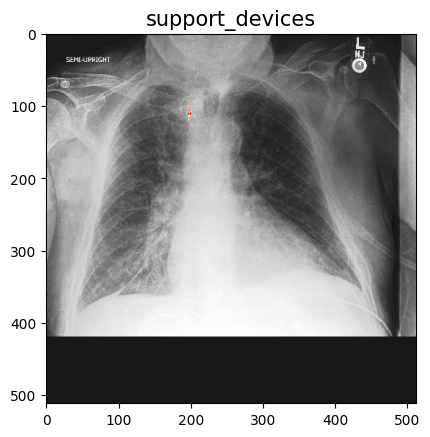

In [13]:
# A single figure is defined as putting this in a loop quickly uses up all system memory.
# This figure is reused for all plots

ig = IntegratedGradients(XtoC)
nt = NoiseTunnel(ig)

guided_gc = GuidedGradCam(XtoC, XtoC.backbone.features.denseblock4.denselayer16[5])

image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0).to(device)
image.requires_grad_(True)
image.grad = None  # Reset gradient

baselines = image * 0

concept_outputs = XtoC(image)

for index in range(concept_outputs.size(1)):
	# get saliecy maps for each concept
	filter_out = torch.zeros_like(concept_outputs)
	filter_out[:,index] += 1

	# get ground truth segmentation
	if index == 0:
		concept_key = "Enlarged Cardiomediastium"
	if index == 1:
		concept_key = "Cardiomegaly"
	if index == 2:
		concept_key = "Airspace Opacity"  #  Lung Opacity
	if index == 3:
		concept_key = "Lung Lesion"
	if index == 4:
		concept_key = "Edema"
	if index == 5:
		concept_key = "Consolidation"
	if index == 6:
		concept_key = "Pneumonia"
	if index == 7:
		concept_key = "Atelectasis"
	if index == 8:
		concept_key = "Pneumothorax"
	if index == 9:
		concept_key = "Pleural Effusion"
	if index == 10:
		concept_key = "Plaural Other"
	if index == 11:
		concept_key = "Fracture"
	if index == 12:
		concept_key = "Support Devices"

	segmentation = get_human_segmentation(segmentation_key, concept_key)
	
	fig, ax = plt.subplots(1)
	
	ax.imshow(orig_imgs[imageId].squeeze())
	
	if segmentation != None:
		segmentation = np.asarray(segmentation.convert("L"))
		segmentation = seg_transform(segmentation, gaussian_blur=3, use_equalizeHist=True, long_side=512, border_pad_str="mean", pixel_mean=128.0, pixel_std=64.0, resize_only=True)
		alpha = np.sum(segmentation, axis=-1) > 0  # only keep segmentation areas
		
		ax.imshow(alpha, cmap=green_alpha, interpolation='none', alpha=0.5)
		
		#ax.imshow(masked_data)

	attribution = nt.attribute(
		image,
		target=int(index),
		baselines=baselines,
		nt_type='smoothgrad_sq',
		nt_samples=25,
		internal_batch_size=25,
		stdevs=0.2
	)
	
	"""
	attribution = guided_gc.attribute(
		image,
		target=int(index),
	)
	"""
	
	attr = heatmap(attribution, cmap_name=seismic_alpha, num_clannels=4)
	
	#attribution = attribution.permute(0, 2, 3, 1).squeeze().detach().cpu().numpy()
	
	#print(attribution.shape)
	
	ax.imshow(attr.squeeze(), cmap=seismic_alpha, interpolation='none')

	#plt.xticks([])
	#plt.yticks([])
	plt.title(label=concept_index_to_string(index), fontsize=15)
	#plt.imshow(attr.squeeze(), cmap='seismic')
	#plt.savefig(f'temp/{i}.png')
	plt.show()

	plt.close()

In [ ]:
#print(XtoC.backbone.features.denseblock4.denselayer16[5])

# A single figure is defined as putting this in a loop quickly uses up all system memory.
# This figure is reused for all plots
FIG, AX = plt.subplots()

guided_gc = GuidedGradCam(XtoC, XtoC.backbone.features.denseblock4.denselayer16[5])

image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0).to(device)
image.requires_grad_(True)
image.grad = None  # Reset gradient

outputs = XtoC(image)

for index in range(outputs.size(1)):
	# get saliecy maps for each concept
	filter_out = torch.zeros_like(outputs)
	filter_out[:,index] += 1

	attribution = guided_gc.attribute(
		image,
		target=int(index),
	)

	attr = heatmap(attribution, cmap_name='seismic')

	plt.xticks([])
	plt.yticks([])
	plt.title(label=concept_index_to_string(index), fontsize=15)
	plt.imshow(attr.squeeze(), cmap='seismic')
	#plt.savefig(f'temp/{i}.png')
	plt.show()

	plt.close()

In [ ]:
XtoC_model_1 = []
XtoC_model_2 = []
XtoC_model_3 = []

for idx, m in enumerate(XtoC.children()):
    if idx < 24:
        XtoC_model_1.append(m)
    elif idx < 46:
        XtoC_model_2.append(m)
    else:
        XtoC_model_3.append(m)

XtoC_model_1 = lrp.Sequential(*XtoC_model_1)
XtoC_model_2 = lrp.Sequential(*XtoC_model_2)
XtoC_model_3 = lrp.Sequential(*XtoC_model_3)

XtoC_model_1.to(device).eval()
XtoC_model_2.to(device).eval()
XtoC_model_3.to(device).eval()

print(XtoC_model_1)
print(XtoC_model_2)
print(XtoC_model_3)

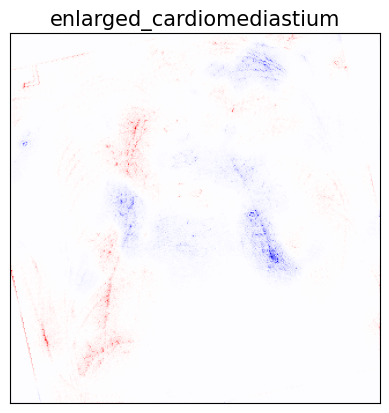

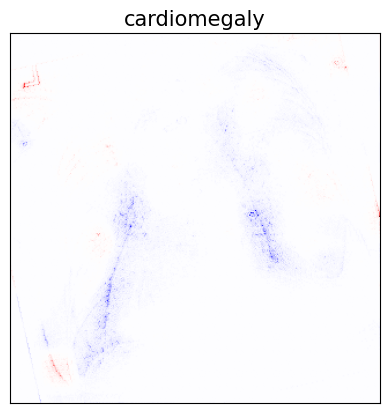

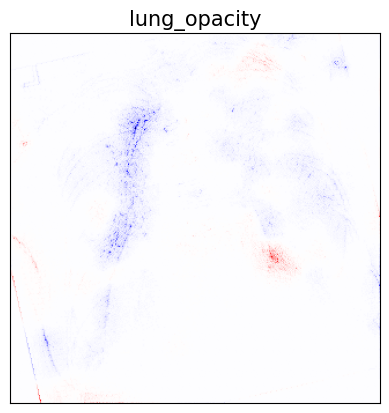

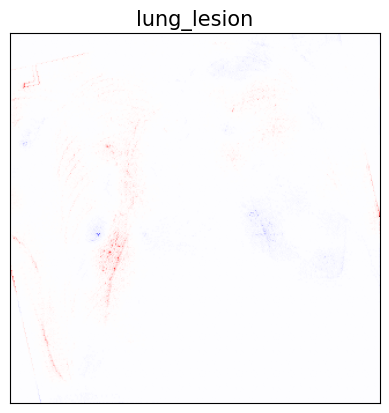

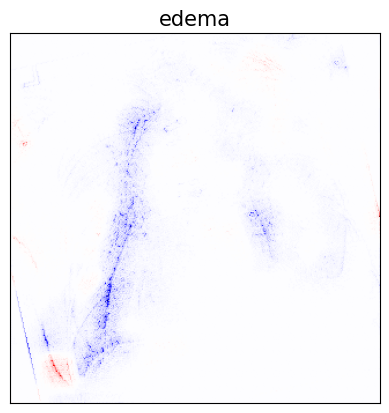

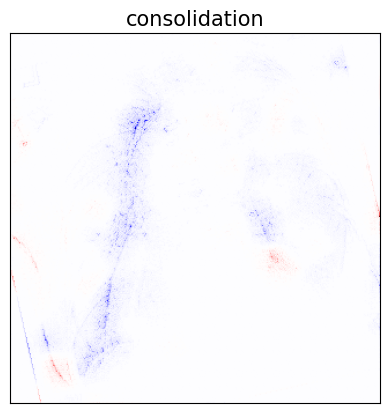

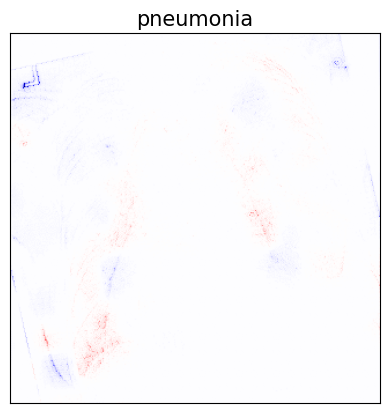

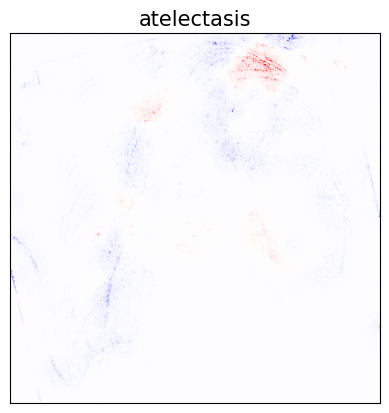

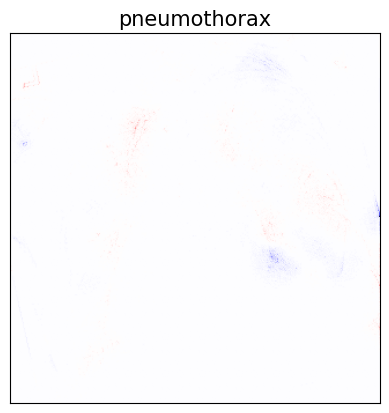

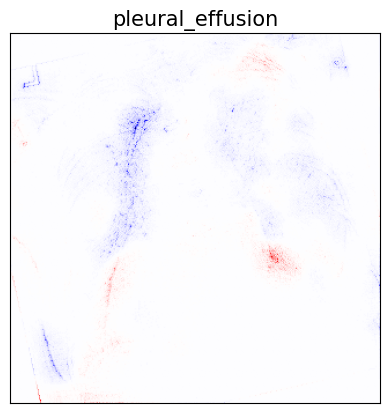

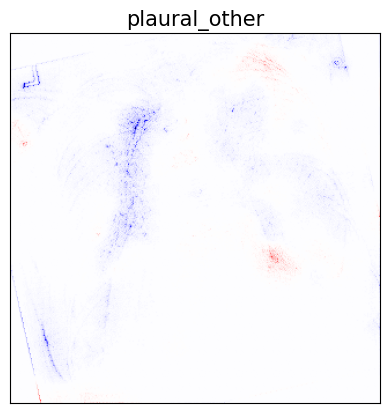

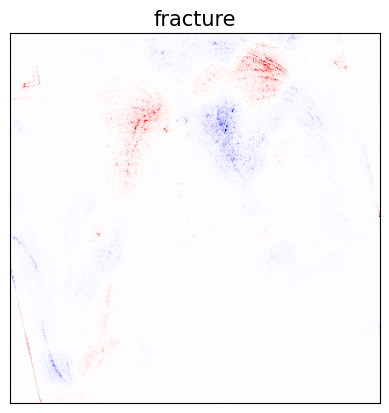

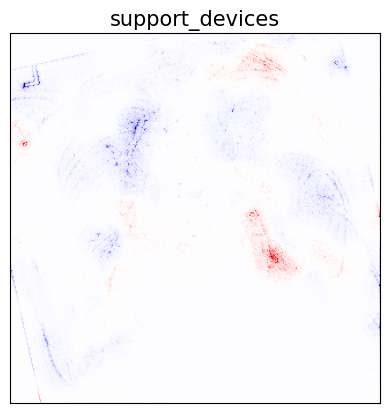

In [21]:
image, concepts = transform(orig_image).to(device), torch.FloatTensor(samples[0][1]).to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

output_1 = XtoC_model_1.forward(image, explain=True, rule="alpha1beta0")
output_2 = XtoC_model_2.forward(output_1, explain=True, rule="epsilon")
pred_concepts = XtoC_model_3.forward(output_2, explain=True, rule="gradient")
    
# get saliecy maps for top 5 concepts
pred_precent_concepts = []
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        pred_precent_concepts.append((idx, i.item()))

pred_precent_concepts = sorted(pred_precent_concepts, key=lambda x: -x[1])

for i in range(pred_concepts.size(1)):
    filter_out = torch.zeros_like(pred_concepts)
    filter_out[:,i] += 1

    # Get the gradient of each input
    image_gradient = torch.autograd.grad(
        pred_concepts,
        image,
        grad_outputs=filter_out,
        retain_graph=True)[0]


    attr = heatmap(image_gradient, cmap_name='seismic')

    plt.xticks([])
    plt.yticks([])
    plt.title(label=concept_index_to_string(i), fontsize=15)
    plt.imshow(attr.squeeze(), cmap='seismic')
    #plt.savefig(f'temp/{i}.png')
    plt.show()

    plt.close() 


# OIS and NIS

In [66]:
import concepts_xai.evaluation.metrics.oracle as oracle
import concepts_xai.evaluation.metrics.niching as niche

def ImputityScore(x_to_c_model, data_loader, mode):
	x_to_c_model.eval()

	c_soft = []
	c_true = []
	with torch.set_grad_enabled(False):
		for images, labels, ground_concepts, extra in tqdm(data_loader, unit="batch"):


			concept_representations = x_to_c_model(images)

			sigmoid_outputs = torch.nn.Sigmoid()(concept_representations.view(concept_representations.size(0), -1))

			c_soft.append(sigmoid_outputs)
			c_true.append(ground_concepts)

	if mode == "oracle":
		score, pred_matrix, oracle_matrix = oracle.oracle_impurity_score(
			c_soft=np.stack(np.concatenate(c_soft, axis=0)),
			c_true=np.stack(np.concatenate(c_true, axis=0)),
			output_matrices=True
		)
		return score, pred_matrix, oracle_matrix
	elif mode == "niche":
		score = niche.niche_impurity_score(
			c_soft=np.stack(np.concatenate(c_soft, axis=0)),
			c_true=np.stack(np.concatenate(c_true, axis=0))
		)
		return score, None, None
	else:
		raise Exception(f"Mode has to have the value 'oracle' or 'niche'")

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 7/7 [00:48<00:00,  6.98s/batch]


2/2 [==============================] - 0s 2ms/step
score: 0.8256257057189942


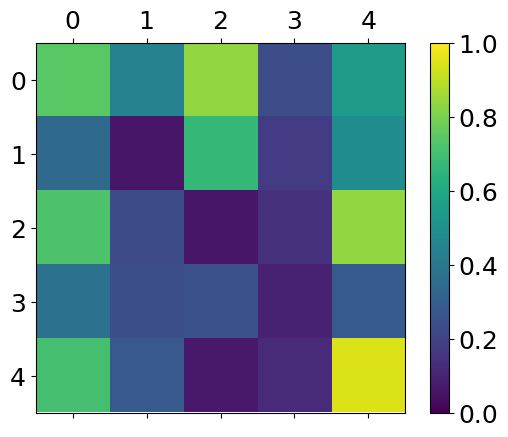

[[0.74545455 0.44444445 0.83809525 0.23529412 0.55151516]
 [0.34545454 0.06111111 0.6666667  0.17892157 0.4848485 ]
 [0.72121215 0.22777778 0.06190476 0.14215687 0.8393939 ]
 [0.37575758 0.23888889 0.25238097 0.09313726 0.28484848]
 [0.7060606  0.2777778  0.06666667 0.12254902 0.94848484]]


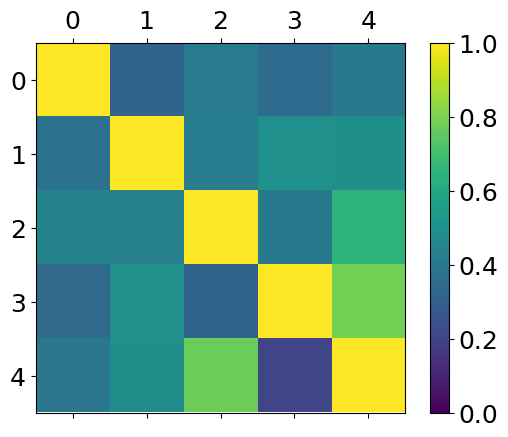

[[1.         0.32386363 0.40714285 0.34871796 0.40128204]
 [0.37698412 1.         0.41904762 0.50384617 0.49615383]
 [0.4484127  0.43560606 1.         0.4051282  0.6474359 ]
 [0.34391534 0.5056818  0.32380953 1.         0.7897436 ]
 [0.39814815 0.4943182  0.77380955 0.21025641 1.        ]]


In [73]:
score, pred_matrix, oracle_matrix = ImputityScore(XtoC, test_loader, mode="oracle")

print("score:", score)

if type(pred_matrix) == np.ndarray:
	for matrix_name in ["pred_matrix", "oracle_matrix"]:
		if matrix_name == "pred_matrix":
			matrix = pred_matrix
		else:
			matrix = oracle_matrix
		fig = plt.figure()
		ax = fig.add_subplot(111)
		cax = ax.matshow(matrix, interpolation='nearest', vmin=0.0, vmax=1.0)
		fig.colorbar(cax)
		plt.show()
		print(matrix)

In [75]:
def normalize_impurity(impurity, n_concepts):
    return impurity / (n_concepts / 2)

norm_fn = lambda x: np.linalg.norm(x, ord='fro')

impurity = normalize_impurity(
	impurity=norm_fn(np.abs(pred_matrix)),
	n_concepts=5
)

print(impurity)

print(pred_matrix.mean())
print(oracle_matrix.mean())

print((pred_matrix * np.eye(5)))
print((pred_matrix * (np.ones((5, 5)) - np.eye(5))))

print((pred_matrix * np.eye(5)).diagonal().mean())

keep_index = np.where(~np.eye(pred_matrix.shape[0],dtype=bool))
print(np.array([pred_matrix[keep_index[0][i], keep_index[1][i]] for i in range(len(keep_index[0]))]).mean())

0.9630759239196778
0.3964321
0.5621322
[[0.74545455 0.         0.         0.         0.        ]
 [0.         0.06111111 0.         0.         0.        ]
 [0.         0.         0.06190476 0.         0.        ]
 [0.         0.         0.         0.09313726 0.        ]
 [0.         0.         0.         0.         0.94848484]]
[[0.         0.44444445 0.83809525 0.23529412 0.55151516]
 [0.34545454 0.         0.66666669 0.17892157 0.4848485 ]
 [0.72121215 0.22777778 0.         0.14215687 0.83939391]
 [0.37575758 0.23888889 0.25238097 0.         0.28484848]
 [0.70606059 0.27777779 0.06666667 0.12254902 0.        ]]
0.3820185035467148
0.40003553


In [54]:
np.ones((5, 5))

array([[1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.]])